# 02 · Pistol → vitória no mapa (D18)

**Pergunta:** quanto vencer os pistols (rounds 1 e 13) decide o mapa?

O win rate bruto por pistols vencidos mistura dois efeitos: o pistol em si e a força do time (time
forte vence mais pistols *e* mais mapas). A regressão logística controla a diferença de Elo
pré-partida:

`venceu o mapa ~ C(pistols vencidos) + diferença de Elo / 100`

Uma linha por mapa, do ponto de vista de um dos times (as duas linhas de um mapa são espelho).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from pipeline import analyses as A
from pipeline import plots as P
from pipeline.stats import fmt

P.setup()
pd.set_option("display.precision", 3)
con = A.connect()  # dbt/metascope.duckdb, do `make build`
A.window(con)

{'first_match': '2025-10-16', 'last_match': '2026-10-11'}

In [2]:
pistol = A.pistol(con)
raw = pd.DataFrame([{"pistols": k, "mapas": e.n, "win rate bruto": e.text(percent=True)}
                    for k, e in pistol["raw"].items()])
model = pd.DataFrame([{"pistols": k, "P(vitória) com Elo igual": e.text(percent=True)}
                      for k, e in pistol["model"]["probabilities"].items()])
odds = pd.DataFrame([{"termo": k, "razão de chances": e.text(2)}
                     for k, e in pistol["model"]["odds_ratios"].items()])
display(raw.merge(model, on="pistols"), odds)
print("mapas no modelo:", pistol["n_maps"])

,pistols,mapas,win rate bruto,P(vitória) com Elo igual
0,0,3307,"27,2% (IC 95% 25,7%–28,7%)","28,1% (IC 95% 26,0%–30,3%)"
1,1,6186,"50,0% (IC 95% 48,8%–51,2%)","50,3% (IC 95% 48,5%–52,1%)"
2,2,3307,"72,8% (IC 95% 71,3%–74,3%)","73,5% (IC 95% 71,3%–75,6%)"


,termo,razão de chances
0,C(pistols)[T.1],"2,59 (IC 95% 2,27–2,95)"
1,C(pistols)[T.2],"7,10 (IC 95% 6,08–8,30)"
2,diff,"1,45 (IC 95% 1,38–1,53)"


mapas no modelo: 6400


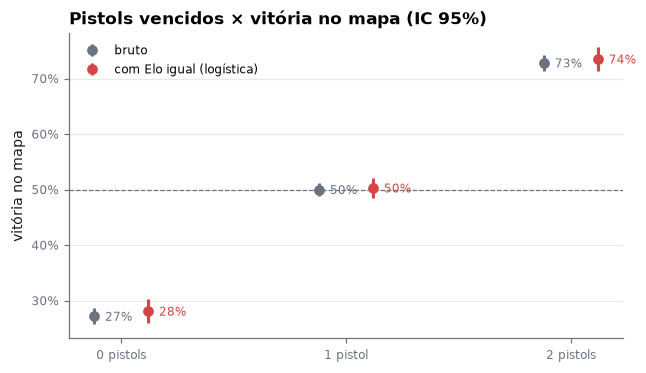

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(3)
for offset, data, color, label in [
    (-0.12, pistol["raw"], P.MUTED, "bruto"),
    (0.12, pistol["model"]["probabilities"], P.ATTACK, "com Elo igual (logística)"),
]:
    v = [data[k].value for k in range(3)]
    lo = [data[k].value - data[k].low for k in range(3)]
    hi = [data[k].high - data[k].value for k in range(3)]
    ax.errorbar(x + offset, v, yerr=[lo, hi], fmt="o", color=color, ms=6, capsize=0,
                elinewidth=2, label=label)
    for xi, vi in zip(x + offset, v):
        ax.annotate(f"{vi:.0%}", (xi, vi), xytext=(7, -3), textcoords="offset points",
                    fontsize=8, color=color)
ax.axhline(0.5, color=P.MUTED, lw=0.8, ls="--")
ax.set_xticks(x, ["0 pistols", "1 pistol", "2 pistols"])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_ylabel("vitória no mapa")
ax.set_title("Pistols vencidos × vitória no mapa (IC 95%)")
ax.legend(loc="upper left")
P.save(fig, "pistol.png")
plt.show()

## Conclusão

In [4]:
pr = pistol["model"]["probabilities"]
orr = pistol["model"]["odds_ratios"]
display(Markdown(f"""
- Com **Elo igual**, quem vence os dois pistols vence o mapa em **{pr[2].text(percent=True)}**; quem
  vence um, em {pr[1].text(percent=True)}; quem perde os dois, em {pr[0].text(percent=True)}.
- Vencer os dois pistols multiplica as chances de vencer o mapa por
  **{orr["C(pistols)[T.2]"].text(2)}** em relação a nenhum; cada 100 pontos de Elo de vantagem, por
  {orr["diff"].text(2)}.
- O efeito do pistol sobrevive ao controle por força do time e é o maior efeito isolado medido no
  projeto. ({pistol["n_maps"]} mapas na janela.)
"""))


- Com **Elo igual**, quem vence os dois pistols vence o mapa em **73,5% (IC 95% 71,3%–75,6%)**; quem
  vence um, em 50,3% (IC 95% 48,5%–52,1%); quem perde os dois, em 28,1% (IC 95% 26,0%–30,3%).
- Vencer os dois pistols multiplica as chances de vencer o mapa por
  **7,10 (IC 95% 6,08–8,30)** em relação a nenhum; cada 100 pontos de Elo de vantagem, por
  1,45 (IC 95% 1,38–1,53).
- O efeito do pistol sobrevive ao controle por força do time e é o maior efeito isolado medido no
  projeto. (6400 mapas na janela.)
